# entropylens quickstart

entropylens measures statistical properties of a neural network's activations: how concentrated or spread out they are, per neuron across a batch and per example across neurons. It reads the activations through forward hooks and leaves the model's outputs and gradients unchanged.

It makes no claim about what a neuron represents. A high value means "this neuron's activations are spread out over the batch" and nothing more. Every estimate also carries a flag for the case where it could not be estimated, so that case is not mistaken for low entropy.

The notebook uses synthetic data and a small MLP. It needs no GPU and no dataset download.

## 1. Install

Installs the library from GitHub into the running kernel. Colab already provides `torch`, `numpy` and `matplotlib`.

In [1]:
%pip install -q "git+https://github.com/SashaRisoluti/entropylens.git"

## 2. Synthetic data and a small MLP

Two Gaussian clusters in 20 dimensions, one per class, and a three-layer MLP with ReLU activations. `x_probe` is a fixed batch of 512 examples used every time entropy is measured, so the numbers are comparable from one step to the next. The seed is fixed.

In [2]:
import math

import torch
import torch.nn as nn

torch.manual_seed(0)

n = 2000
x = torch.cat([torch.randn(n // 2, 20) + 1.0, torch.randn(n // 2, 20) - 1.0])
y = torch.cat([torch.ones(n // 2), torch.zeros(n // 2)]).long()
x_probe = x[torch.randperm(n)[:512]]

model = nn.Sequential(
    nn.Linear(20, 64), nn.ReLU(),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 2),
)
print(model)

Sequential(
  (0): Linear(in_features=20, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=2, bias=True)
)


## 3. The functional API

Both functions take a `(batch, neurons)` tensor of activations. Here that tensor is the output of the first ReLU layer of the untrained model: 512 examples, 64 neurons.

**Batch-wise entropy** answers "how spread out is this neuron across the batch?" and returns one value per neuron. How to read the fields:

- `entropy`: in nats, from a 32-bin histogram of the neuron's values over their 1%-99% quantile range, with a Miller-Madow bias correction.
- `normalized`: `entropy` divided by its upper bound `log(min(N, bins))`, so it lies in [0, 1]. This is the scale to use when comparing layers.
- `reliable`: `False` means "not estimable", not "low entropy". `True` means no warning sign was found; it is not a guarantee (see the limitations in the README).
- `reason`: a code that explains the flag; `REASON_LABELS` turns it into text (used in section 6).

In [3]:
from entropylens import REASON_LABELS, batch_wise_entropy, per_example_entropy

with torch.no_grad():
    acts = model[:2](x_probe)          # output of the first ReLU: (512, 64)

r = batch_wise_entropy(acts)
print("shape of each field:", tuple(r.entropy.shape))
print(f"upper bound log(min(N, bins)): {math.log(min(r.n, r.bins)):.3f} nats")
print("entropy (nats), first 5 neurons:", r.entropy[:5])
print("normalized, first 5 neurons:    ", r.normalized[:5])
print("reliable, first 5 neurons:      ", r.reliable[:5])
print(f"reliable neurons: {int(r.reliable.sum())} of {r.reliable.numel()}")

shape of each field: (64,)
upper bound log(min(N, bins)): 3.466 nats
entropy (nats), first 5 neurons: tensor([2.3778, 2.3905, 2.1829, 2.0958, 1.8721])
normalized, first 5 neurons:     tensor([0.6861, 0.6898, 0.6298, 0.6047, 0.5402])
reliable, first 5 neurons:       tensor([True, True, True, True, True])
reliable neurons: 64 of 64


**Per-example entropy** answers "how spread out is this example's activation pattern across neurons?" and returns one value per example. Each row is rescaled to sum to 1 and its entropy is taken across the 64 neurons; `normalized` divides by the bound `log(M)`.

The `strategy` argument is required. It says how negative activations are handled before the rescaling: `"relu"` sets them to zero, `"abs"` takes absolute values. These activations come from a ReLU, so `"relu"` is the matching choice.

`valid` is `False` for a row that is all zeros after the strategy. Its entropy is `NaN`, not 0.

In [4]:
p = per_example_entropy(acts, "relu")
print("shape of each field:", tuple(p.entropy.shape))
print("entropy (nats), first 5 examples:", p.entropy[:5])
print("normalized, first 5 examples:    ", p.normalized[:5])
print(f"valid rows: {int(p.valid.sum())} of {p.valid.numel()}")

shape of each field: (512,)
entropy (nats), first 5 examples: tensor([3.3134, 2.9081, 3.1248, 3.1759, 3.2948])
normalized, first 5 examples:     tensor([0.7967, 0.6993, 0.7514, 0.7637, 0.7922])
valid rows: 512 of 512


## 4. Tracking during training

`EntropyTracker` registers forward hooks on the model. While it is attached, every forward pass stores one record per tracked layer. The loop below follows the pattern in the README: train as usual, then at the end of each epoch attach the tracker, run one forward pass on the probe batch under `torch.no_grad()`, and detach. Each epoch adds one step to the history.

`layer_filter` restricts tracking to the two ReLU layers. They are named `"1"` and `"3"`, their positions in the `nn.Sequential`.

In [5]:
from entropylens import EntropyTracker

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
tracker = EntropyTracker(model, layer_filter=lambda name, module: isinstance(module, nn.ReLU))

for epoch in range(30):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(x), y)   # normal training step, untracked
    loss.backward()
    optimizer.step()

    tracker.attach()
    with torch.no_grad():
        model(x_probe)                                # one tracked forward = one step
    tracker.detach()

print(f"training loss at the last step: {loss.item():.4f}")
print("records per layer:", {name: len(records) for name, records in tracker.records.items()})

training loss at the last step: 0.1505
records per layer: {'1': 30, '3': 30}


`report().summary()` returns one dictionary per layer for the last tracked step, on the normalized scale:

- `batch_wise_normalized_mean` / `_std`: mean and standard deviation of the per-neuron normalized entropy.
- `reliable_fraction`: share of neurons whose estimate is flagged reliable. Read the mean together with this number: the mean is taken over all neurons of the layer, including the ones flagged unreliable.
- `n`: batch size of the tracked forward pass.
- `per_example_normalized_mean` / `per_example_sem`: mean per-example normalized entropy over valid rows, and its standard error.
- `per_example_invalid_rows`: number of rows with undefined per-example entropy.

In [6]:
for layer, row in tracker.report().summary().items():
    print(f"layer '{layer}'")
    for key, value in row.items():
        print(f"    {key:<30}{value:.4g}")

layer '1'
    batch_wise_normalized_mean    0.6473
    batch_wise_normalized_std     0.06442
    reliable_fraction             1
    n                             512
    per_example_normalized_mean   0.7618
    per_example_sem               0.001174
    per_example_invalid_rows      0
layer '3'
    batch_wise_normalized_mean    0.5987
    batch_wise_normalized_std     0.2362
    reliable_fraction             0.9375
    n                             512
    per_example_normalized_mean   0.7239
    per_example_sem               0.002956
    per_example_invalid_rows      0


`report().depth_trend()` gives the mean normalized batch-wise entropy of each layer, in order of depth.

In [7]:
for layer, value in tracker.report().depth_trend():
    print(f"layer '{layer}': {value:.4f}")

layer '1': 0.6473
layer '3': 0.5987


## 5. The dashboard

`viz.dashboard` draws the tracked history in one figure:

- top: mean normalized entropy per layer at each step. An `x` marks a step where some neurons of that layer are unreliable.
- middle: one heatmap per tracked layer, neurons by steps. Grey cells are unreliable estimates; they are not given a colour.
- bottom: the neurons with the highest normalized entropy at the final step, ranked among reliable neurons only, with the number of excluded neurons.

In the output stored with this notebook, a few neurons of layer `'3'` turn grey during training: their values on the probe batch no longer vary over that quantile range, so there is nothing to estimate. The dark cells next to them are low values that could still be estimated.

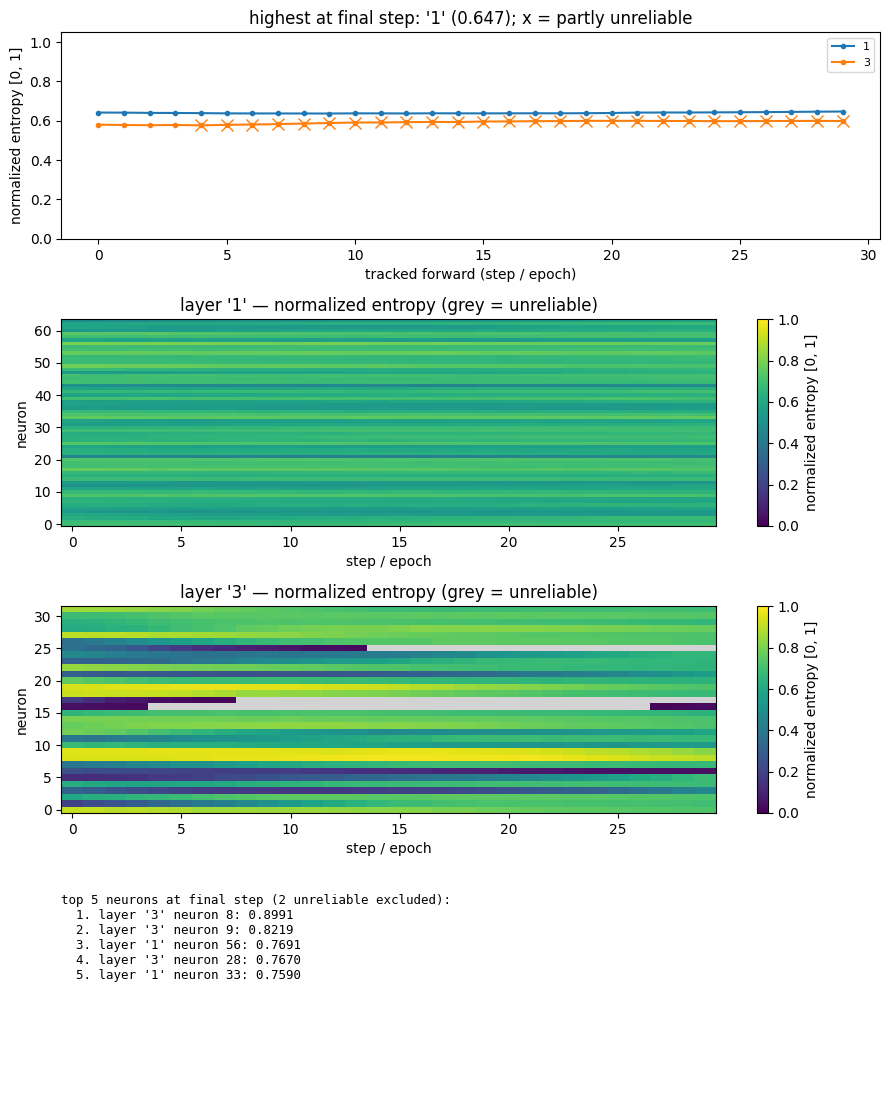

In [8]:
from entropylens import viz

fig = viz.dashboard(tracker, k=5)

## 6. The `reliable` flag on degenerate cases

Some inputs do not allow an estimate. The library flags them instead of returning a number that looks like a measurement. Below are four hand-made neurons with 512 samples each:

- `healthy`: normally distributed values.
- `two-valued`: half zeros, half ones. Its entropy is low, and it can be estimated.
- `constant` and `dead`: a single repeated value (0.7, and 0.0).

In [9]:
torch.manual_seed(0)
neurons = {
    "healthy": torch.randn(512),
    "two-valued": torch.arange(512).remainder(2).float(),
    "constant": torch.full((512,), 0.7),
    "dead": torch.zeros(512),
}
r = batch_wise_entropy(torch.stack(list(neurons.values()), dim=1))   # (512, 4)

for name, h, norm, ok, code in zip(neurons, r.entropy, r.normalized, r.reliable, r.reason):
    print(f"{name:<11} entropy={h:.3f}  normalized={norm:.3f}  reliable={bool(ok)!s:<5}  reason: {REASON_LABELS[code]}")

healthy     entropy=3.307  normalized=0.954  reliable=True   reason: ok
two-valued  entropy=0.694  normalized=0.200  reliable=True   reason: ok
constant    entropy=0.000  normalized=0.000  reliable=False  reason: degenerate (zero quantile range)
dead        entropy=0.000  normalized=0.000  reliable=False  reason: degenerate (zero quantile range)


How to read this: `two-valued` has a low normalized entropy with `reliable=True`, so it is a measurement. `constant` and `dead` also show 0.000, but with `reliable=False` and the reason "degenerate": there is no spread to build a histogram from, so the 0.000 is a placeholder and means "not estimable". Check `reliable` before interpreting or ranking values.

A batch can also be too small. With the default 32 bins the flag requires at least 90 samples; below that, values are still returned but every neuron is flagged.

In [10]:
small = batch_wise_entropy(torch.randn(16, 3))
print("normalized:", small.normalized)
print("reliable:  ", small.reliable)
print("reason:    ", [REASON_LABELS[code] for code in small.reason])

normalized: tensor([0.9872, 1.0000, 1.0000])
reliable:   tensor([False, False, False])
reason:     ['N below reliability threshold', 'N below reliability threshold', 'N below reliability threshold']


Per-example entropy has the same distinction. A row with one active neuron has entropy 0 and is valid. A row with no active neuron has no defined entropy: it is `NaN` with `valid=False`. (The valid zero is printed as `-0.`; it is equal to 0.)

In [11]:
rows = torch.tensor([[1.0, 1.0, 1.0, 1.0],    # uniform across neurons: maximum entropy
                     [5.0, 0.0, 0.0, 0.0],    # one active neuron: entropy 0, valid
                     [0.0, 0.0, 0.0, 0.0]])   # nothing active: undefined
p = per_example_entropy(rows, "relu")
print("normalized:", p.normalized)
print("valid:     ", p.valid)

normalized: tensor([1., -0., nan])
valid:      tensor([ True,  True, False])


## 7. Where next

- [README](https://github.com/SashaRisoluti/entropylens#readme): the two metrics side by side, the tracker's guarantees, bootstrap confidence intervals (`confidence_interval`), the documented limitations of the `reliable` flag, and the experimental TensorFlow and JAX backends.
- [MATH_DECISIONS.md](https://github.com/SashaRisoluti/entropylens/blob/main/MATH_DECISIONS.md): the specification of both estimators and the numeric evidence behind each choice (written in Italian).